* Vol-JEPA


#### Goals
- 3D volume을 anisotropic patch로 토큰화
- I-JEPA와 반대로 context 비율이 작은 이유를 마스크에서 확인
- teacher는 볼륨 전체, student는 context, loss는 Smooth L1


#### Contents
1. Implementation
    <br>1.1 공식 설정과 노트북 설정
    <br>1.2 3D mask
2. Experiment
    <br>2.1 짧은 학습

Vol-JEPA는 NeuroVFM encoder pretraining이다. 공개 설정(`train/config/pretrain.yaml`)은 ViT-B, 패치 4×16×16, token dim 1024, content 738에 3D positional encoding 30을 concat해 768, predictor depth 12, EMA 0.994→1.0, loss Smooth L1, context scale은 MRI 0.25 / CT 0.20 이다.

이 노트북은 같은 데이터 흐름을 CPU에서 한 스텝 돌리도록 줄였다. 패치 2×4×4, content 72 + PE 24 = 96, depth 2.


## 1. Implementation


In [1]:
import sys
from pathlib import Path

import torch

candidates = [Path.cwd(), Path.cwd() / "jepa"]
for cand in candidates:
    module_dir = cand / "modules"
    if module_dir.is_dir():
        sys.path.insert(0, str(module_dir))
        break
else:
    raise FileNotFoundError("jepa/modules 를 찾지 못했다. 노트북 cwd 를 ai-lab 또는 ai-lab/jepa 로 둔다.")

torch.manual_seed(0)
device = torch.device("cpu")
print("device", device)

from vol_jepa import VolJEPA, sample_vol_masks

model = VolJEPA(patch_size=(2, 4, 4), content_dim=72, pe_dim=24, depth=2, num_heads=4, enc_scale=0.25).to(device)
volume = torch.rand(2, 1, 8, 32, 32, device=device)
tokens, coords = model.tokenize(volume)
grid = (
    int(coords[:, 0].max()) + 1,
    int(coords[:, 1].max()) + 1,
    int(coords[:, 2].max()) + 1,
)
context_idx, target_idx, view = sample_vol_masks(grid, enc_scale=0.25)
print("volume", tuple(volume.shape), "tokens", tuple(tokens.shape), "grid D,H,W", grid)
print(f"context {context_idx.numel()} ({context_idx.numel()/tokens.size(1):.2f}), target {target_idx.numel()}")


device cpu
volume (2, 1, 8, 32, 32) tokens (2, 256, 32) grid D,H,W (4, 8, 8)
context 72 (0.28), target 184


#### 1.2 3D mask

1은 context, 2는 target이다. target cuboid는 depth 전체를 덮고, context가 `enc_scale`보다 크면 depth slab를 잘라낸다. I-JEPA의 context(약 85%)와 비율이 반대다.


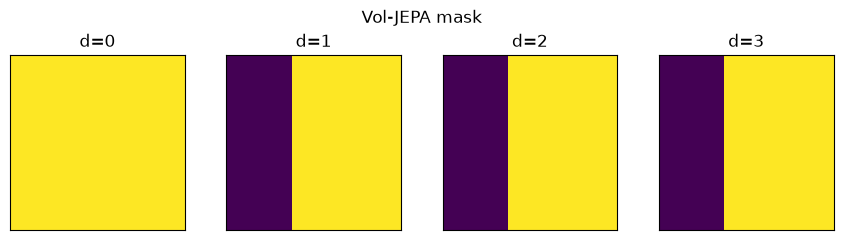

smooth l1 0.3886


In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, view.size(0), figsize=(2.2 * view.size(0), 2.4))
for depth_idx, ax in enumerate(axes):
    ax.imshow(view[depth_idx].numpy(), vmin=1, vmax=2, interpolation="nearest")
    ax.set_title(f"d={depth_idx}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Vol-JEPA mask")
fig.tight_layout()
plt.show()

loss = model(volume)
print("smooth l1", round(loss.item(), 4))


## 2. Experiment

#### 2.1 짧은 학습

볼륨은 합성 데이터다. teacher momentum은 공식 스케줄의 시작값 0.994를 그대로 쓴다.


In [3]:
optimizer = torch.optim.AdamW(model.trainable_parameters(), lr=1e-3, weight_decay=0.05)
history = []
for step in range(4):
    optimizer.zero_grad()
    loss = model(volume)
    loss.backward()
    optimizer.step()
    model.update_target(momentum=0.994)
    history.append(loss.item())
print([round(v, 4) for v in history])


[0.3904, 0.3109, 0.2693, 0.2434]
